# Session 8 — Computer Vision: Why Images Need a Different Network

In Session 6 a network took a handful of numbers as input. An image has thousands: a 28×28 picture has 784 pixel values. We could feed them to the same kind of network after flattening them into a row, but that throws away the layout, and the layout is most of what an image is. A **convolutional neural network (CNN)** keeps it.

This session compares a flattened dense network with a small CNN on handwritten digits. The comparison that matters is not their score on ordinary test digits. It is what happens when the digits are moved a few pixels.

**By the end of the session you should be able to:**

1. describe what a convolution filter does, and compute one by hand;
2. explain why a CNN needs far fewer parameters than a dense network on the same image;
3. read the shift test and say what the CNN's spatial design buys and what it doesn't.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib`, `torch` and `torchvision`. The first run downloads the MNIST digits (about 11 MB compressed) into `~/.cache/ai_journey`. The saved outputs came from a laptop GPU, where the notebook took 32 seconds. On a CPU the networks take a few minutes to train, and your numbers may differ slightly from the ones quoted in the text.

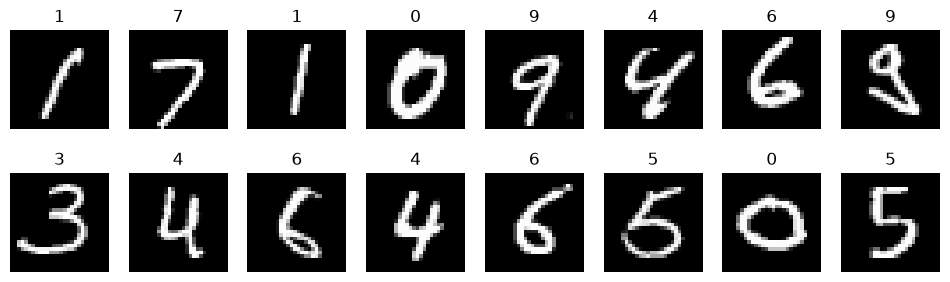

One image: (1, 28, 28) = 1 channel of 28 x 28 pixels. Values run from 0.0 to 1.0
Training images: 10000  Test images: 10000  Device: cuda


In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # lets the GPU repeat a run exactly (see the last line of this cell)

import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision.datasets import MNIST

SEED, DATA = 0, pathlib.Path.home() / ".cache" / "ai_journey"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
train_set, test_set = MNIST(DATA, train=True, download=True), MNIST(DATA, train=False, download=True)
x_all, y_all = (train_set.data / 255.0).unsqueeze(1), train_set.targets  # shape (images, channels, height, width)
x_test, y_test = (test_set.data / 255.0).unsqueeze(1), test_set.targets

keep = torch.tensor(np.random.default_rng(SEED).permutation(len(x_all))[:10_000])  # 10,000 training digits keep the notebook quick on a laptop
x_train, y_train = x_all[keep], y_all[keep]

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, image, label in zip(axes.ravel(), x_train, y_train):
    ax.imshow(image[0], cmap="gray")
    ax.set_title(int(label))
    ax.axis("off")
plt.show()
print("One image:", tuple(x_train[0].shape), "= 1 channel of 28 x 28 pixels. Values run from", x_train.min().item(), "to", x_train.max().item())
print("Training images:", len(x_train), " Test images:", len(x_test), " Device:", DEVICE)
torch.use_deterministic_algorithms(True)

## 1. The data: MNIST handwritten digits

MNIST is the standard small image dataset: 28×28 grey images of handwritten digits 0 to 9. Yann LeCun and colleagues used it in 1998 to show that convolutional networks, the subject of this session, read handwriting better than the other methods of the time. A grey image is a grid of numbers, one per pixel, from 0 (black) to 1 (white). Each image here has shape (1, 28, 28): PyTorch puts the number of colour **channels** first, then height and width. A colour photo would have 3 channels.

We use 10,000 of the 60,000 training digits to keep the notebook quick, and all 10,000 test digits.

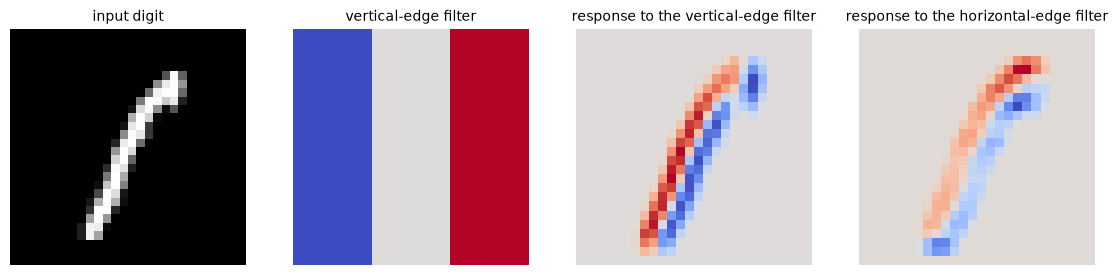

In [2]:
def convolve2d(image, kernel):
    kh, kw = kernel.shape
    out = np.zeros((image.shape[0] - kh + 1, image.shape[1] - kw + 1))
    for row in range(out.shape[0]):
        for col in range(out.shape[1]):
            out[row, col] = np.sum(image[row:row + kh, col:col + kw] * kernel)
    return out


vertical_edge = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=float)
horizontal_edge = vertical_edge.T
digit = x_train[0, 0].numpy()

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, picture, title in zip(axes, [digit, vertical_edge, convolve2d(digit, vertical_edge), convolve2d(digit, horizontal_edge)],
                              ["input digit", "vertical-edge filter", "response to the vertical-edge filter", "response to the horizontal-edge filter"]):
    ax.imshow(picture, cmap="gray" if title == "input digit" else "coolwarm")
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.show()

## 2. A convolution, computed by hand

A **filter** is a small grid of weights, here 3×3. To apply it, place it over a 3×3 patch of the image, multiply each weight by the pixel under it, add up the nine products, and write the sum down. Then slide it one pixel along and repeat. The result is a new image, called a feature map, that shows where in the picture the filter's pattern occurs. `convolve2d` does exactly this with two loops.

The vertical-edge filter has −1 in its left column and +1 in its right column, so it responds strongly where the image goes from dark to bright going left to right. In the third picture, the left side of the stroke is red (dark to bright, a strong positive response) and the right side is blue (bright to dark, negative). The horizontal-edge filter, in the fourth picture, is the same filter turned on its side. It responds more weakly along the stroke, which is mostly upright, and most strongly at its top end, where the edge runs sideways.

The filter above was written by hand. In a CNN the values in each filter are learned, in the same way as any other weights. The important point is that the **same nine numbers are used at every position** in the image.

> **Pause:** the next cell builds a CNN with two convolution layers (16 filters, then 32, each 3×3) and a dense network that connects all 784 pixels to 128 units. Which one needs more parameters, and by roughly how much?
>
> - **A.** The CNN needs more.
> - **B.** The dense network, about twice as many.
> - **C.** The dense network, about eight times as many.
> - **D.** The dense network, about a hundred times as many.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**C.** The dense network has 101,770 parameters and the CNN 12,810, about eight times fewer, because a filter's weights are reused at every position.

</details>

In [3]:
def dense_model():
    torch.manual_seed(SEED)  # same starting weights on every run
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))


def cnn_model():
    torch.manual_seed(SEED)
    return nn.Sequential(nn.Conv2d(1, 16, 3), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(16, 32, 3), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(800, 10))


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


def summary(model):
    """Pass one blank image through the layers and print each layer's output shape and parameter count."""
    x = torch.zeros(1, 1, 28, 28)
    for layer in model:
        x = layer(x)
        print(f"{type(layer).__name__:10s} output {str(tuple(x.shape[1:])):14s} parameters {count_parameters(layer):>6,}")
    print(f"{'total':10s} {'':21s} parameters {count_parameters(model):>6,}")


summary(cnn_model())
print("\nParameters in the dense network:", f"{count_parameters(dense_model()):,}")

Conv2d     output (16, 26, 26)   parameters    160
ReLU       output (16, 26, 26)   parameters      0
MaxPool2d  output (16, 13, 13)   parameters      0
Conv2d     output (32, 11, 11)   parameters  4,640
ReLU       output (32, 11, 11)   parameters      0
MaxPool2d  output (32, 5, 5)     parameters      0
Flatten    output (800,)         parameters      0
Linear     output (10,)          parameters  8,010
total                            parameters 12,810

Parameters in the dense network: 101,770


## 3. Counting parameters

Reusing the same filter everywhere is why a CNN is small. Our CNN has two convolution layers (16 filters, then 32 filters, each 3×3), each followed by max pooling, which keeps the largest value in every 2×2 block and halves the width and height. The first layer's 16 filters need only 160 parameters (16 × 9 weights + 16 biases). The whole network has 12,810.

The summary lists every layer with the shape of what comes out of it: 16 feature maps of 26×26 after the first convolution, 32 maps of 5×5 before the last layer. ReLU, pooling and flattening have no parameters.

The dense network flattens the image into 784 numbers and connects them all to 128 units. That one layer alone needs 784 × 128 + 128 = 100,480 parameters, and the whole network has 101,770, about eight times as many as the CNN.

In the dense network every pixel has its own separate weights for every unit. A vertical stroke in the top-left corner and the same stroke in the bottom-right are, to that network, unrelated patterns.

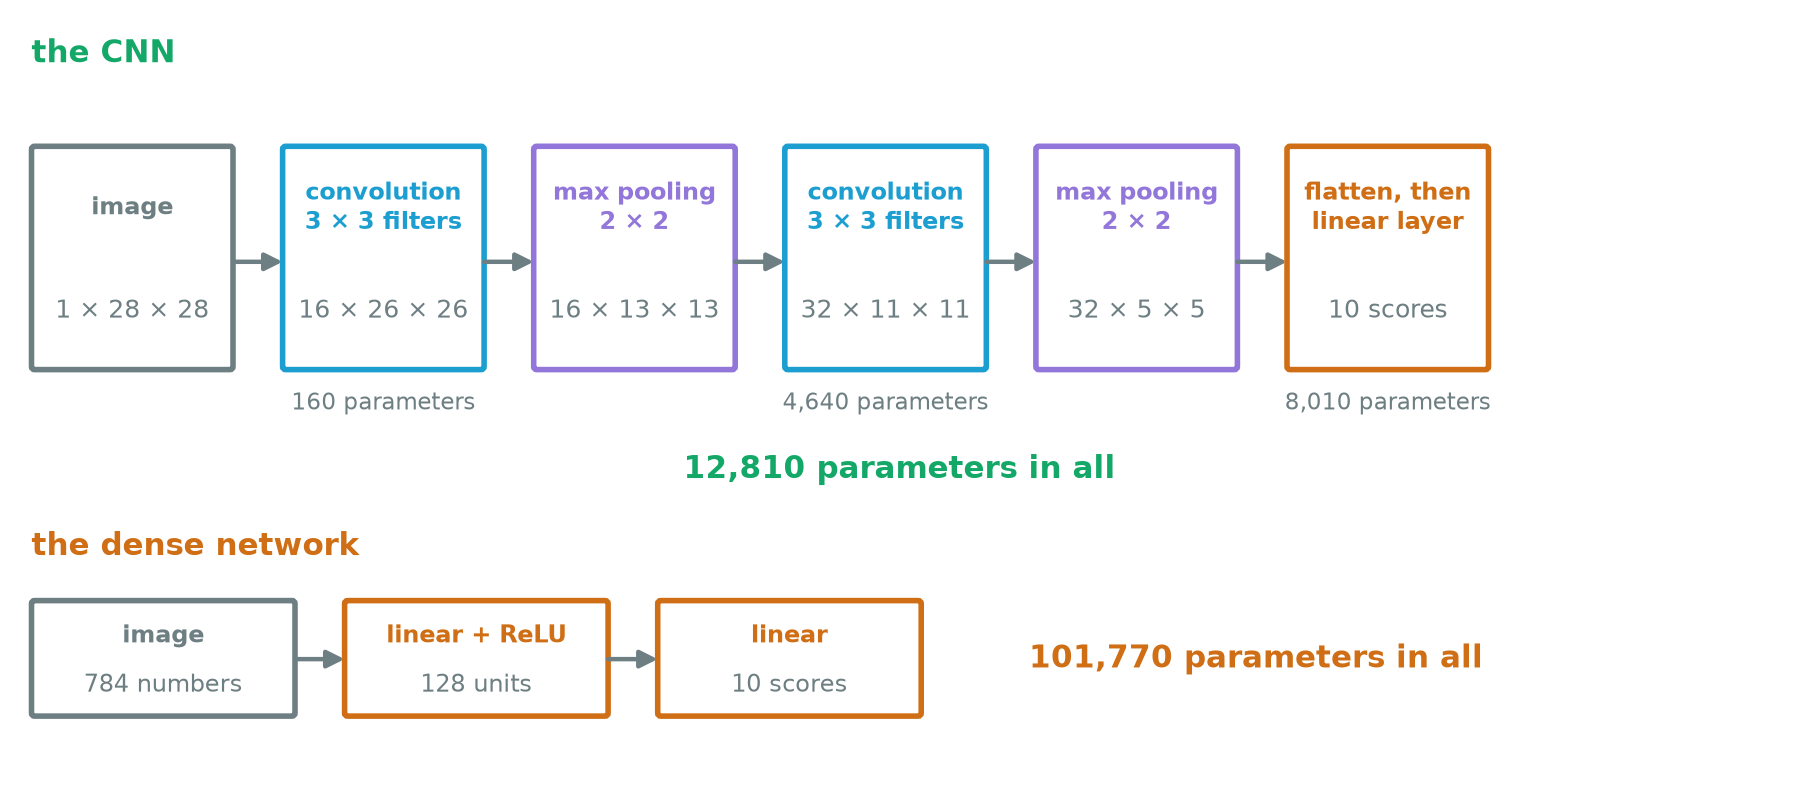

*Figure 8.1 — The CNN as a stack of blocks, with the shape of what comes out of each. The same small filters are reused at every position, so the whole network has 12,810 parameters; the dense network on the same image has 101,770.*

In [4]:
def predict(model, x):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(batch.to(DEVICE)).argmax(dim=1).cpu() for batch in x.split(1000)])


def accuracy(model, x, y):
    return (predict(model, x) == y).float().mean().item()


def train(model, epochs=8, batch_size=128):
    """Adam with its default learning rate, cross-entropy loss, the last 10% of the training digits held out for validation."""
    torch.manual_seed(SEED)
    model = model.to(DEVICE)
    n_fit = int(len(x_train) * 0.9)
    x_fit, y_fit = x_train[:n_fit].to(DEVICE), y_train[:n_fit].to(DEVICE)
    optimizer, loss_fn = torch.optim.Adam(model.parameters()), nn.CrossEntropyLoss()
    for epoch in range(epochs):
        model.train()
        for batch in torch.randperm(n_fit, device=DEVICE).split(batch_size):
            loss = loss_fn(model(x_fit[batch]), y_fit[batch])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    print(f"  validation accuracy after {epochs} epochs: {accuracy(model, x_train[n_fit:], y_train[n_fit:]):.3f}")
    return model


dense, cnn = train(dense_model()), train(cnn_model())
for name, model in [("dense", dense), ("CNN", cnn)]:
    print(f"{name:6s} parameters {count_parameters(model):>7,}   test accuracy {accuracy(model, x_test, y_test):.3f}")

  validation accuracy after 8 epochs: 0.919


  validation accuracy after 8 epochs: 0.970
dense  parameters 101,770   test accuracy 0.931
CNN    parameters  12,810   test accuracy 0.973


## 4. Training both under the same conditions

Both networks see the same 10,000 digits, the same 8 epochs, the same optimiser (Adam) and batch size, and the same random seed, with the last 10% of the training digits held out for validation. Only the architecture differs. The training loop is Session 7's, on the GPU when there is one.

With ten classes the network ends in ten numbers, one score per digit. `nn.CrossEntropyLoss` turns them into ten probabilities with softmax (the right use of it, across the classes of one example, unlike Session 7's bug) and takes minus the log of the probability of the true digit, the ten-class version of Session 6's loss. The prediction is the digit with the highest score.

On the 10,000 test digits the dense network scores 0.931 and the CNN scores 0.973, with eight times fewer parameters. The CNN is better here, but a gap of 4 points on a dataset where both do well doesn't tell us much about *why*. The next test does.

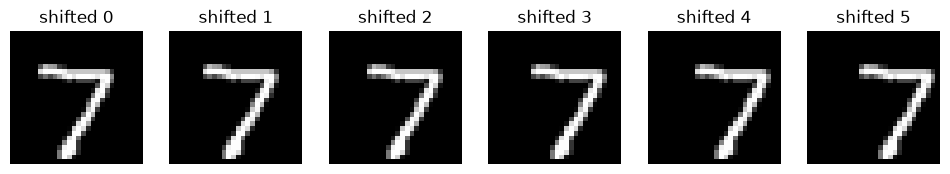

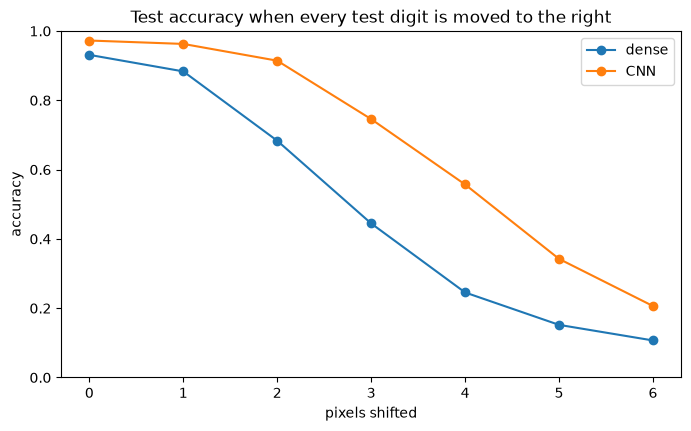

pixels shifted      0      1      2      3      4      5      6
dense           0.931  0.883  0.683  0.445  0.245  0.152  0.107
CNN             0.973  0.963  0.914  0.746  0.557  0.342  0.206

Share of test digits that lose some ink off the right edge: {1: '0%', 2: '1%', 3: '6%', 4: '16%', 5: '30%', 6: '46%'}


In [5]:
def shift_right(images, pixels):
    shifted = torch.zeros_like(images)
    shifted[..., pixels:] = images[..., :images.shape[-1] - pixels] if pixels else images
    return shifted


fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for ax, pixels in zip(axes, range(6)):
    ax.imshow(shift_right(x_test[:1], pixels)[0, 0], cmap="gray")
    ax.set_title(f"shifted {pixels}")
    ax.axis("off")
plt.show()

shifts = range(0, 7)
robustness = pd.DataFrame({"dense": [accuracy(dense, shift_right(x_test, s), y_test) for s in shifts],
                           "CNN": [accuracy(cnn, shift_right(x_test, s), y_test) for s in shifts]}, index=pd.Index(shifts, name="pixels shifted"))
robustness.plot(marker="o", figsize=(8, 4.5), title="Test accuracy when every test digit is moved to the right", ylabel="accuracy", ylim=(0, 1))
plt.show()
print(robustness.round(3).T.to_string())
print("\nShare of test digits that lose some ink off the right edge:", {s: f"{(x_test[..., 28 - s:] > 0).any(dim=(1, 2, 3)).float().mean().item():.0%}" for s in range(1, 7)})

## 5. The shift test

We move every test digit to the right by 0 to 6 pixels. Neither network is trained on shifted digits, so this asks how much each one has learned about digit *shapes* as opposed to digit *positions*.

> **Pause:** which network will lose more accuracy when the digits move 3 pixels, and why?
>
> - **A.** The CNN, because its filters are fitted to particular positions.
> - **B.** The dense network, because every pixel position has its own weights.
> - **C.** Both about the same.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**B.** At a shift of 3 pixels the dense network falls from 0.931 to 0.445, below half, while the CNN falls from 0.973 to 0.746.

</details>

The pictures show one digit shifted by 0 to 5 pixels. The table gives the accuracy:

| pixels shifted | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| dense | 0.931 | 0.883 | 0.683 | 0.445 | 0.245 | 0.152 | 0.107 |
| CNN | 0.973 | 0.963 | 0.914 | 0.746 | 0.557 | 0.342 | 0.206 |

At a shift of 2 pixels the CNN has lost 5.9 points (0.973 to 0.914) and the dense network 24.8 points (0.931 to 0.683). At 3 pixels the CNN scores 0.746 and the dense network 0.445, which is below half. The dense network has to recognise the digit's pixels in the wrong place, while the CNN's filters look for the same stroke patterns wherever they appear.

The CNN is far from immune. It falls to 0.557 at 4 pixels, because its last layer still reads the position of the features. Part of the loss at large shifts is not the network's fault: the printed line shows that 16% of the test digits already lose some ink off the right edge at a shift of 4 pixels, 30% at 5 and 46% at 6. Spatial structure helps, and the usual remedy for what is left is to show the network shifted digits during training (data augmentation).

The CNN gets 275 of 10,000 test digits wrong.


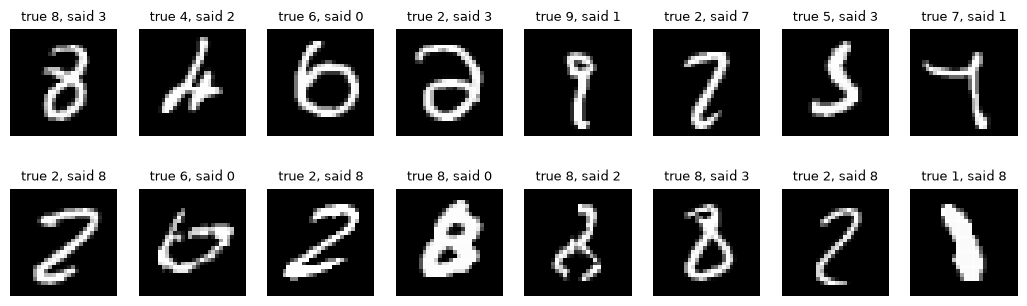

Most common mix-ups (true -> predicted: count):
true  predicted
7     2            22
2     8            15
7     9            13
8     3            11
2     7             9
7     3             8


In [6]:
predictions = predict(cnn, x_test).numpy()
labels = y_test.numpy()
wrong = np.flatnonzero(predictions != labels)
print(f"The CNN gets {len(wrong)} of {len(labels):,} test digits wrong.")

fig, axes = plt.subplots(2, 8, figsize=(13, 3.8))
for ax, i in zip(axes.ravel(), wrong[:16]):
    ax.imshow(x_test[i, 0], cmap="gray")
    ax.set_title(f"true {labels[i]}, said {predictions[i]}", fontsize=9)
    ax.axis("off")
plt.show()

confused = pd.crosstab(pd.Series(labels[wrong], name="true"), pd.Series(predictions[wrong], name="predicted")).stack().sort_values(ascending=False)
print("Most common mix-ups (true -> predicted: count):")
print(confused.head(6).to_string())

## 6. Looking at the CNN's mistakes

The CNN gets 275 of the 10,000 test digits wrong. The most common mix-ups are 7 read as 2 (22 times), 2 as 8 (15), 7 as 9 (13) and 8 as 3 (11).

Several of the 16 errors shown are digits a person would also hesitate over: the 4 drawn as a scribble (said 2), the thick slanted bar labelled 1 (said 8), and the 8 with its loops filled in (said 0). Others look clear to us, such as the 6 in the top row (said 0) and several of the 2s read as 8, so the network is not simply making human-like errors. Looking at the images is how you tell which mistakes come from unclear data and which from the model.

## What to take away

- A convolution filter is a small grid of weights slid over the whole image. It uses the same weights at every position.
- That sharing makes a CNN much smaller than a dense network on the same image: 12,810 parameters against 101,770 here.
- The benefit appears most clearly when the data changes in a way the architecture expects. When digits moved by 2 pixels, the CNN lost 5.9 points and the dense network 24.8.
- A CNN is not shift-proof. For the remaining gap, augment the training data.
- A high test score is not enough. Check how the model behaves when the input changes, and look at its mistakes.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## The convolution formula

For an image $X$ and a kernel $K$ of size $k_h\times k_w$, the output at position $(i,j)$ is

$$
Y_{i,j}=\sum_{u=0}^{k_h-1}\sum_{v=0}^{k_w-1}K_{u,v}\,X_{i+u,\,j+v}.
$$

Deep-learning libraries call this operation "convolution", although strictly it is cross-correlation, because the kernel is not flipped.

## Channels and parameters

A filter spans every input channel and produces one output channel. A layer with $C_{\text{in}}$ input channels, $C_{\text{out}}$ filters and a $k_h\times k_w$ kernel has

$$
k_h\,k_w\,C_{\text{in}}\,C_{\text{out}}+C_{\text{out}}
$$

parameters. Our second layer: $3\cdot3\cdot16\cdot32+32=4{,}640$, matching the summary. PyTorch stores this layer's weights as a tensor of shape (32, 16, 3, 3): output channels, input channels, height, width.

## Output size, padding and stride

Without padding, a $3\times3$ filter can't be centred on border pixels, so each convolution shrinks the image by 2 pixels in each direction: 28 becomes 26, and after pooling 13, then 11, then 5 (see the summary). In one dimension, with input size $I$, padding $P$, kernel size $K$ and stride $S$, the output size is

$$
O=\left\lfloor\frac{I+2P-K}{S}\right\rfloor+1.
$$

Padding adds a border of zeros; stride sets how far the filter moves between positions.

## Pooling

Max pooling replaces each block (here $2\times2$) with its largest value. It reduces the size of the feature maps and makes the result less sensitive to small shifts of a feature inside the block. Some modern networks replace pooling with strided convolutions, or average each whole feature map into a single value (global average pooling) before the final layer.

The last cell tests this. It retrains the CNN with three different heads on the same convolution layers and measures accuracy at shifts of 0, 2 and 4 pixels. The flattening head keeps the position of every feature, so it is the most accurate on centred digits and loses the most when they move. Global average pooling, which averages each feature map into one number, throws position away: it is the least accurate on centred digits (0.720) but changes less with shift. Global max pooling, which keeps only the strongest response of each filter, is in between and holds up best: it scores 0.870 on centred digits and still 0.781 at 4 pixels, where the flattening head has fallen to 0.557. Which trade-off is right depends on whether the position of a feature matters for the task.

In [7]:
def cnn_with_head(head, features):
    torch.manual_seed(SEED)
    return nn.Sequential(nn.Conv2d(1, 16, 3), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(16, 32, 3), nn.ReLU(), nn.MaxPool2d(2), head, nn.Linear(features, 10))


# the feature maps are 5 x 5 at this point, so a 5 x 5 pool covers the whole map: one number per filter
heads = {"flatten (used above)": (nn.Flatten(), 800),
         "global average pooling": (nn.Sequential(nn.AvgPool2d(5), nn.Flatten()), 32),
         "global max pooling": (nn.Sequential(nn.MaxPool2d(5), nn.Flatten()), 32)}
head_results = {}
for name, (head, features) in heads.items():
    print(name)
    model = train(cnn_with_head(head, features))
    head_results[name] = [accuracy(model, shift_right(x_test, s), y_test) for s in (0, 2, 4)]
pd.DataFrame(head_results, index=["0 px", "2 px", "4 px"]).T.round(3)

flatten (used above)


  validation accuracy after 8 epochs: 0.970
global average pooling


  validation accuracy after 8 epochs: 0.697
global max pooling


  validation accuracy after 8 epochs: 0.868


,0 px,2 px,4 px
flatten (used above),0.973,0.914,0.557
global average pooling,0.720,0.671,0.589
global max pooling,0.870,0.851,0.781
